# Plotting a run with `PlotSink`

`PlotSink` is an output sink that draws a run's events as PNGs:

- each **scalar** name (`train/loss/total`, `eval/val/auroc`) becomes one line plot of
  its value against the training step, drawn when the sink closes;
- each **table** holding a `ROCCurve`, `PRCurve` or `ConfusionMatrix` is drawn in that
  graph's standard form as soon as it arrives, one PNG per step (other named number
  columns become plain line plots).

A plot of your own is a table type that draws itself: a dataclass with a `draw(axes)`
method, built at each validation like the curves above.

Here a linear classifier learns which side of the line y = x a point lies on. The sink
plots its loss and validation AUROC, and, at every validation, its ROC curve,
precision-recall curve and confusion matrix, and a custom plot of the boundary it learned.

Run from `examples/`. `lwfm` isn't an installed package yet, so put the repository root on the import path.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

## 1. The data

Points scattered around the line y = x. The label says whether a point lies above the
line, but the boundary is noisy near the line, so even the best linear classifier can't
reach an AUROC of 1.

In [2]:
import torch


def make_batches(count: int, batch_size: int = 64, seed: int = 0) -> list[dict]:
    """`count` batches of 2D points around y = x, labelled 1 above the line."""
    generator = torch.Generator().manual_seed(seed)
    batches = []
    for _ in range(count):
        x = torch.rand(batch_size, generator=generator) * 2 - 1  # in [-1, 1]
        y = x + 0.5 * torch.randn(batch_size, generator=generator)  # around y = x
        # Above the line, with a noisy boundary (std 0.3)
        noise = 0.3 * torch.randn(batch_size, generator=generator)
        label = (y > x + noise).long()
        batches.append(
            {
                "inputs": {"point": torch.stack([x, y], dim=1)},
                "targets": {"label": label},
            }
        )
    return batches


train_loader = make_batches(10)
val_loader = make_batches(5, seed=1)

## 2. A linear classifier

One `nn.Linear(2, 1)` gives a logit per point; the boundary it learns is a line. Binary
cross-entropy needs float targets and `BinaryAUROC` needs integer ones, so a two-line
loss module converts the label.

Metrics give one number per validation. Curves need every score in the validation set,
so a `CurveBinding` collects the values it reads over the whole set, then passes them in
order to the function it is given: here `ROCCurve.from_scores(logits, labels)`.

In [3]:
import torch.nn.functional as F
from torch import nn
from torchmetrics.classification import BinaryAUROC

from lwfm.core.graph import ExecutionGraph, ModelNode
from lwfm.core.losses import LossBinding, LossComposer
from lwfm.evaluation.metrics import CurveBinding, MetricBinding
from lwfm.results.curves import ConfusionMatrix, PRCurve, ROCCurve
from lwfm.training import Trainer, seed_everything


class BinaryCrossEntropy(nn.Module):
    def forward(self, logit, label):
        return F.binary_cross_entropy_with_logits(logit, label.float())


seed_everything(0)
classifier = ModelNode(
    "classifier",
    nn.Sequential(nn.Linear(2, 1), nn.Flatten(0)),  # [B, 2] -> [B] logits
    inputs="inputs.point",
    outputs="logit",
)
graph = ExecutionGraph([classifier])
loss = LossComposer(
    [LossBinding("bce", BinaryCrossEntropy(), ["classifier.logit", "targets.label"])]
)
reads = ["classifier.logit", "targets.label"]
# BinaryAUROC applies the sigmoid itself when given logits
metrics = [MetricBinding("auroc", BinaryAUROC(), reads)]
curves = [
    CurveBinding("roc", ROCCurve.from_scores, reads),
    CurveBinding("pr", PRCurve.from_scores, reads),
    CurveBinding(
        "confusion",
        lambda s, y: ConfusionMatrix.from_scores(s, y, ["below", "above"]),  # logit > 0
        reads,
    ),
]

## 3. Training, with the plots as one more sink

`PlotSink` sits next to `LocalFileSink` in the router, so it sees every event: the
losses and learning rate the trainer logs, and what the `Evaluator` logs at each
validation (here after each epoch): the AUROC as a `scalar`, and each curve as a `table`
named `eval/val/roc`, `eval/val/pr` and `eval/val/confusion`. `PlotSink` draws each curve
in its standard form, e.g. the ROC curve with its AUC and the chance diagonal.

The learned boundary is a custom plot, so it gets a table type of its own:

- `from_outputs` builds it from what the `CurveBinding` reads: the points, labels and
  logits of the whole validation set. The classifier is linear, so
  logit = w_x * x + w_y * y + b holds exactly, and a least-squares fit of the logits
  recovers the line.
- `draw(axes)` draws it. `PlotSink` calls it for any table that has one.

In [4]:
from dataclasses import dataclass

from matplotlib.axes import Axes
from torch import Tensor


@dataclass(frozen=True)
class Boundary:
    """Validation points coloured by label, and the line where the logit is 0."""

    points: list[list[float]]
    labels: list[int]
    line: list[float]  # w_x, w_y, b

    @classmethod
    def from_outputs(cls, points: Tensor, labels: Tensor, logits: Tensor) -> "Boundary":
        inputs = torch.cat([points, torch.ones(len(points), 1)], dim=1)  # [x, y, 1]
        line = torch.linalg.lstsq(inputs, logits[:, None]).solution.flatten()
        return cls(points.tolist(), labels.tolist(), line.tolist())

    def draw(self, axes: Axes) -> None:
        (x, y), (w_x, w_y, b) = torch.tensor(self.points).T, self.line
        axes.scatter(x, y, c=self.labels, cmap="coolwarm", s=8)
        # w_x * x + w_y * y + b = 0, at x = -1 and x = 1
        axes.plot([-1, 1], [(w_x - b) / w_y, (-w_x - b) / w_y], "k", label="learned")
        axes.plot([-1, 1], [-1, 1], "k:", label="y = x")
        axes.set(xlabel="x", ylabel="y", xlim=(-1, 1))
        axes.legend()


point_reads = ["inputs.point", "targets.label", "classifier.logit"]
curves.append(CurveBinding("boundary", Boundary.from_outputs, point_reads))

In [5]:
import json
import tempfile

from lwfm.results.plots import PlotSink
from lwfm.results.router import OutputRouter
from lwfm.results.sinks import LocalFileSink

run_dir = Path(tempfile.mkdtemp()) / "roc_demo"

with OutputRouter(LocalFileSink(run_dir), PlotSink(run_dir / "plots")) as sink:
    result = Trainer(device="cpu", max_epochs=10, log_every_n_steps=5).fit(
        graph,
        train_loader,
        loss,
        torch.optim.SGD(classifier.parameters(), lr=0.5),
        val_loader=val_loader,
        metrics=metrics,
        curves=curves,
        output_sink=sink,
    )

step = result.global_step
roc_steps = []
for line in (run_dir / "events.jsonl").open():
    event = json.loads(line)
    if event["name"] == "eval/val/roc":  # stored as its fields
        roc_steps.append(event["step"])
        roc_auc = event["value"]["auc"]
    if event["name"] == "eval/val/boundary":
        fitted_line = event["value"]["line"]  # the last validation's
print("ROC curves at steps:", roc_steps)
print(
    "final AUROC:",
    round(result.history[-1][1]["auroc"], 3),
    "| final ROC AUC:",
    round(roc_auc, 3),
)
linear = classifier.module[0]
print("learned (w_x, w_y, b):", [*linear.weight[0].tolist(), linear.bias.item()])
print("fitted  (w_x, w_y, b):", fitted_line)

ROC curves at steps: [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
final AUROC: 0.887 | final ROC AUC: 0.887
learned (w_x, w_y, b): [-1.9303215742111206, 2.595590114593506, -0.055780936032533646]
fitted  (w_x, w_y, b): [-1.9303216934204102, 2.595590591430664, -0.05578094720840454]


The weights have opposite signs and similar sizes, so the logit is roughly
proportional to y - x: the classifier has found the line y = x.

## 4. The plots

`PlotSink` names each PNG after its event, `/` replaced by `_`, plus the step for a
table: the first and last ROC curves are `eval_val_roc_step10.png` and
`eval_val_roc_step100.png`.

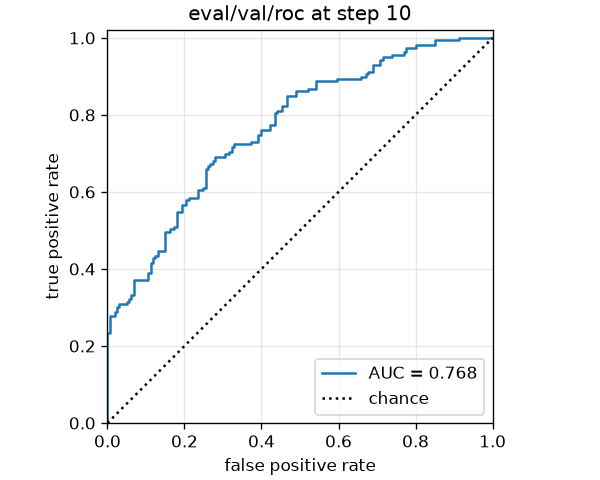

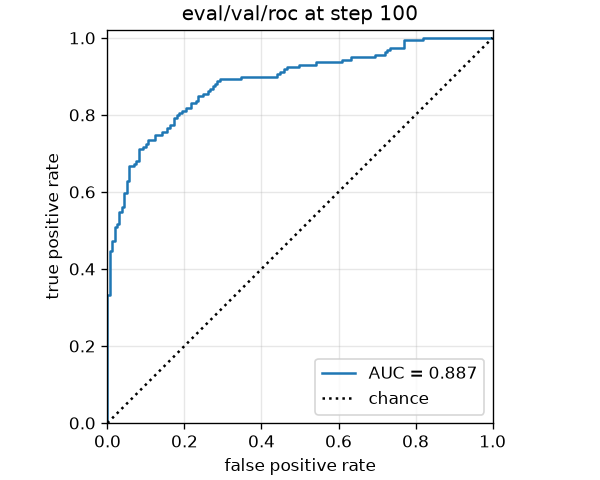

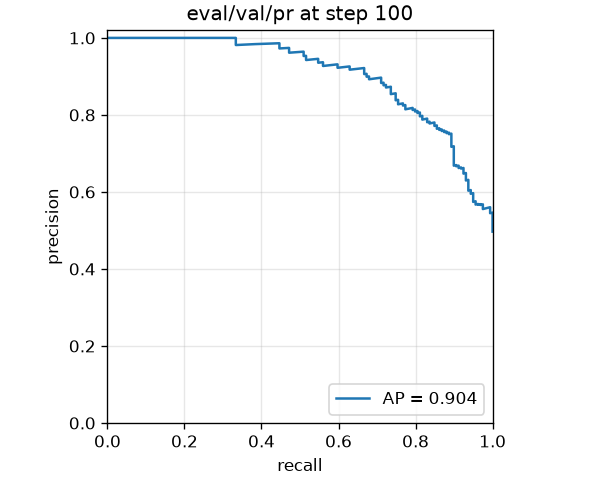

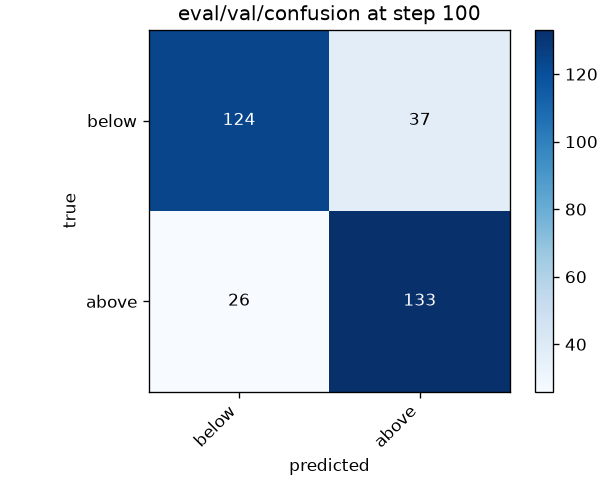

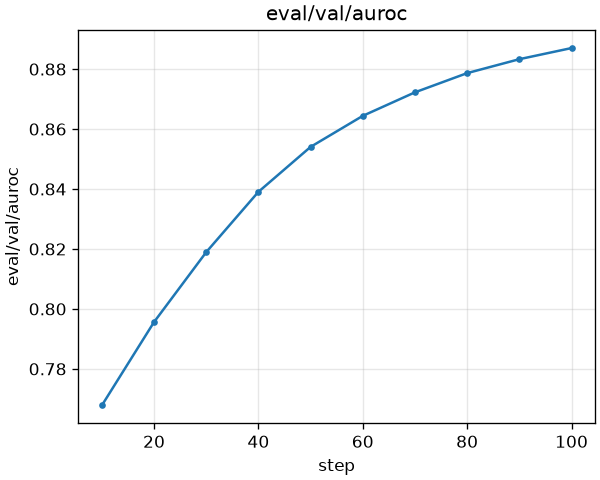

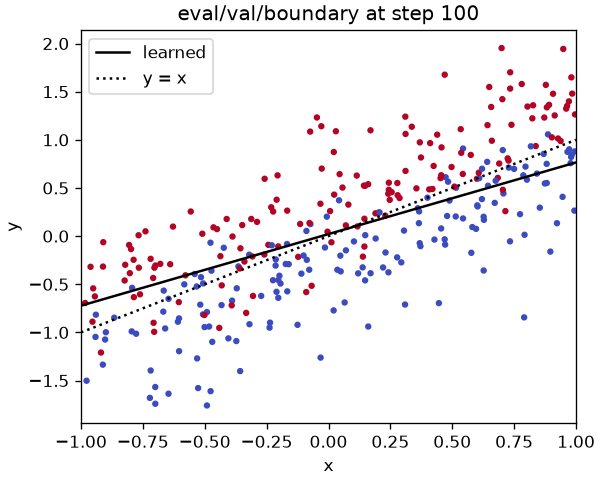

In [6]:
from IPython.display import Image, display

names = [
    "eval_val_roc_step10",  # after the first epoch
    f"eval_val_roc_step{step}",
    f"eval_val_pr_step{step}",
    f"eval_val_confusion_step{step}",
    "eval_val_auroc",
    f"eval_val_boundary_step{step}",
]
for name in names:
    display(Image(filename=run_dir / "plots" / f"{name}.png"))

## 5. Notes

- **What gets plotted.** Scalars need a step; a scalar logged without one (e.g. a final
  test score) has nothing to plot against and is skipped. Tables must be a `ROCCurve`,
  `PRCurve`, `ConfusionMatrix`, a value with a `draw(axes)` method such as `Boundary`,
  or a dict of at least two equal-length numeric columns; other tables and messages
  (such as `trainer/settings`) are ignored.
- **Plots that aren't tables**, e.g. one drawn once after training from the weights, are
  drawn with matplotlib and saved with
  `save_artifact(run_dir, "plots/name.png", figure.savefig, sink, name=...)`. It writes
  the file, then sends an `artifact` event so `events.jsonl` lists it.
- **When plots are drawn.** A table is drawn when it arrives, so curves can be checked
  while a long run is still going. Scalar plots are drawn on close, so they cover the
  whole run; a crashed run still gets them, since `OutputRouter` closes every sink on
  the way out.
- **Curves cost memory.** A `CurveBinding` keeps every score in the validation set until
  the curve is built, unlike a metric's running totals: 50k ImageNet logits take 200 MB.
- **The record is plain data.** `LocalFileSink` stores each curve as its fields, e.g.
  `{"fpr": [...], "tpr": [...], "auc": 0.887}`, so the plots can be redrawn from the run
  directory. The AUC and average precision come from torchmetrics' `BinaryAUROC` and
  `BinaryAveragePrecision`.
- **Malformed curves fail when built**, e.g. `ROCCurve` with unequal `fpr` and `tpr`
  lengths, rather than being skipped by the sink.